<a href="https://colab.research.google.com/github/AM0ya/Clase_Programacion/blob/main/Validacion_Evaluacion_Seleccion_269712.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Carga de Bibliotecas, Conjunto de Datos y Análisis Exploratorio de los Datos

In [47]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score



df = pd.read_csv("/content/drive/MyDrive/Maestria/Programación/Semana 13/TCGA_GBM_LGG_Mutations_all.csv")




### 2. 📊 Análisis exploratorio de datos (EDA)

In [49]:
print('dimenciones del data frame rows & columns=',df.shape)


dimenciones del data frame rows & columns= (862, 27)


In [50]:
df.describe()

,Grade,Project,Case_ID,Gender,Age_at_diagnosis,Primary_Diagnosis,Race,IDH1,TP53,ATRX,...,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
count,862,862,862,862,862,862,862,862,862,862,...,862,862,862,862,862,862,862,862,862,862
unique,2,2,862,3,838,7,6,2,2,2,...,2,2,2,2,2,2,2,2,2,2
top,LGG,TCGA-LGG,TCGA-DU-8164,Male,--,Glioblastoma,white,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
freq,499,499,1,499,5,360,766,448,508,642,...,815,821,824,833,834,834,835,839,839,840


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 862 entries, 0 to 861
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Grade              862 non-null    object
 1   Project            862 non-null    object
 2   Case_ID            862 non-null    object
 3   Gender             862 non-null    object
 4   Age_at_diagnosis   862 non-null    object
 5   Primary_Diagnosis  862 non-null    object
 6   Race               862 non-null    object
 7   IDH1               862 non-null    object
 8   TP53               862 non-null    object
 9   ATRX               862 non-null    object
 10  PTEN               862 non-null    object
 11  EGFR               862 non-null    object
 12  CIC                862 non-null    object
 13  MUC16              862 non-null    object
 14  PIK3CA             862 non-null    object
 15  NF1                862 non-null    object
 16  PIK3R1             862 non-null    object
 1

In [52]:
df['Grade'].value_counts()

,count
Grade,
LGG,499
GBM,363


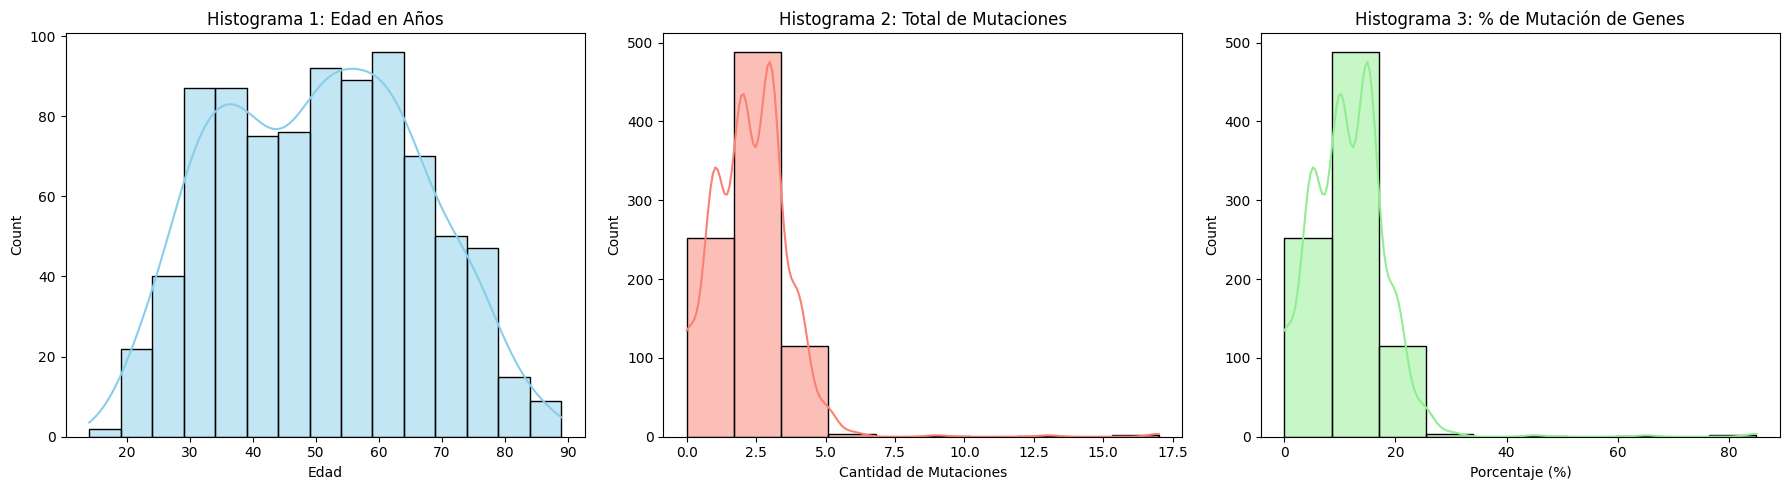

In [53]:
import seaborn as sns
import matplotlib.pyplot as plt
import re

# Identificar columnas de genes (todas excepto las demográficas/clase)
gene_cols = [c for c in df.columns if c not in ['Grade', 'Project', 'Case_ID', 'Gender', 'Age_at_diagnosis', 'Age_years', 'Primary_Diagnosis', 'Race']]

# Convertir mutaciones a binario (1 si está MUTATED, 0 en caso contrario)
df_numeric = df.copy()
for col in gene_cols:
    df_numeric[col] = df_numeric[col].apply(lambda x: 1 if x == 'MUTATED' else 0)

# Extraer la edad en años desde 'Age_at_diagnosis' (ej. "51 years 108 days" -> 51.0)
def extract_years(val):
    if pd.isna(val) or val == '--':
        return None
    match = re.search(r'(\d+)\s*year', str(val))
    return float(match.group(1)) if match else None

df_numeric['Age_years'] = df_numeric['Age_at_diagnosis'].apply(extract_years)

# Crear variables numéricas adicionales para el histograma
# 1. Total de mutaciones por paciente
df_numeric['Total_Mutations'] = df_numeric[gene_cols].sum(axis=1)
# 2. Porcentaje de mutaciones sobre los genes analizados
df_numeric['Mutation_Percentage'] = (df_numeric['Total_Mutations'] / len(gene_cols)) * 100

# Graficar 3 Histogramas
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_numeric['Age_years'].dropna(), bins=15, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Histograma 1: Edad en Años')
axes[0].set_xlabel('Edad')

sns.histplot(df_numeric['Total_Mutations'], bins=10, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Histograma 2: Total de Mutaciones')
axes[1].set_xlabel('Cantidad de Mutaciones')

sns.histplot(df_numeric['Mutation_Percentage'], bins=10, kde=True, ax=axes[2], color='lightgreen')
axes[2].set_title('Histograma 3: % de Mutación de Genes')
axes[2].set_xlabel('Porcentaje (%)')

plt.tight_layout()
plt.show()

/tmp/ipykernel_2899/4256897065.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Grade', y='Age_years', data=df_numeric, palette='Set2')


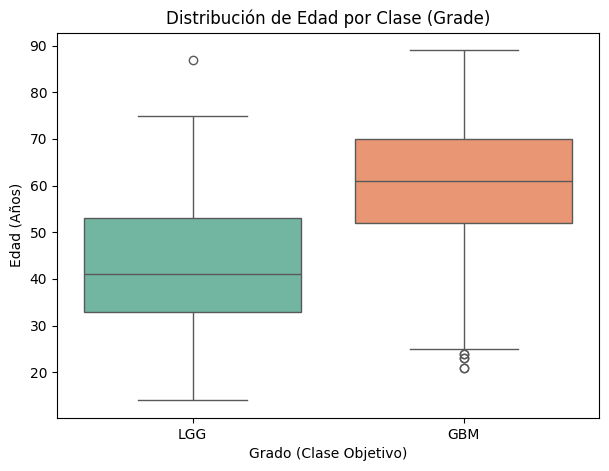

In [54]:
# Boxplot de la edad por clase (Grade)
plt.figure(figsize=(7, 5))
sns.boxplot(x='Grade', y='Age_years', data=df_numeric, palette='Set2')
plt.title('Distribución de Edad por Clase (Grade)')
plt.xlabel('Grado (Clase Objetivo)')
plt.ylabel('Edad (Años)')
plt.show()

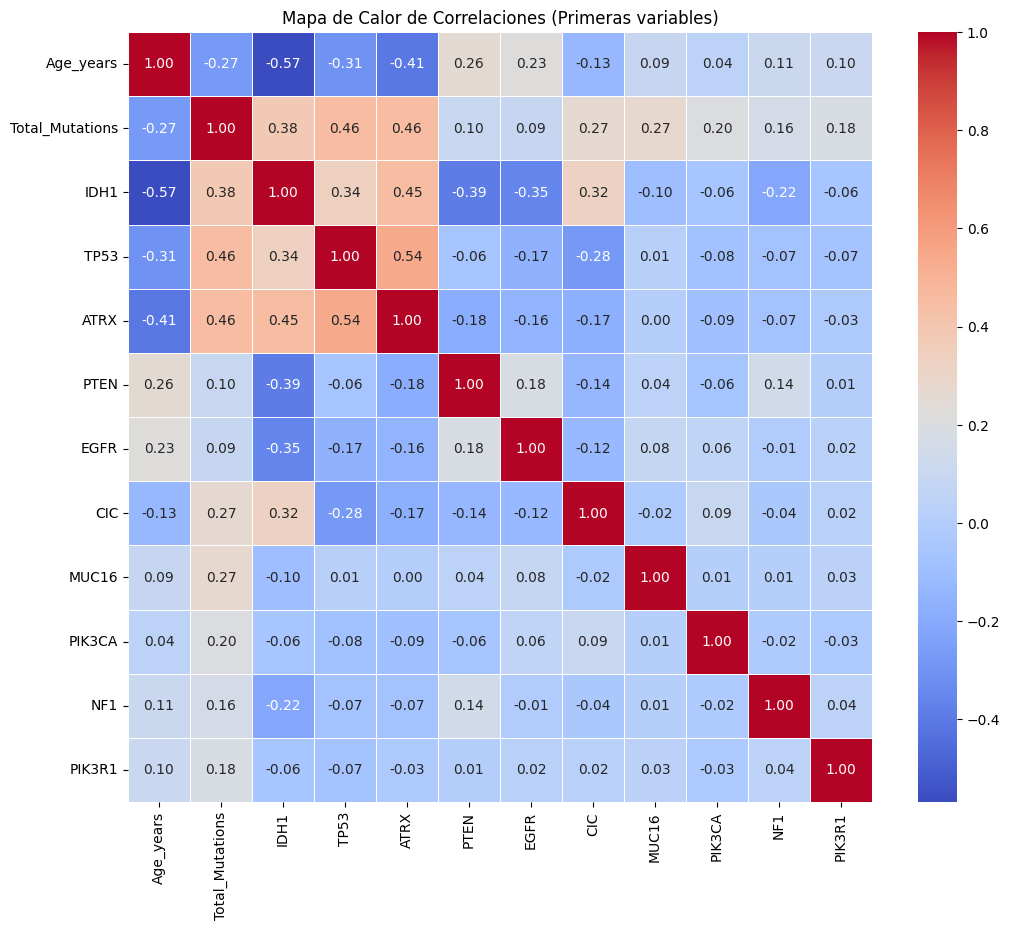

In [55]:
# Mapa de calor de correlaciones entre las variables de mutación y edad
cols_to_correlate = ['Age_years', 'Total_Mutations'] + gene_cols[:10]  # Mostramos las primeras 10 mutaciones para mejor legibilidad
plt.figure(figsize=(12, 10))
sns.heatmap(df_numeric[cols_to_correlate].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Mapa de Calor de Correlaciones (Primeras variables)')
plt.show()

### 🧠 Reflexiones del Análisis Exploratorio (EDA):
- **¿Existen clases desbalanceadas?** No de forma severa. El dataset contiene un **58%** de casos LGG (499) y un **42%** de GBM (363). Esta distribución permite un entrenamiento estable sin técnicas forzadas de remuestreo.
- **¿Qué atributos parecen más informativos?**
  - Al observar el Boxplot, los pacientes diagnosticados con **GBM (Glioblastoma)** tienden a ser notablemente mayores (mediana alrededor de 60 años) que aquellos con **LGG** (mediana alrededor de 40 años).
  - Ciertas mutaciones como **IDH1** y **TP53** suelen tener una alta correlación e importancia clínica para diferenciar entre astrocitomas y glioblastomas primarios.

### 3. Gráfica de Errores en Entrenamiento y Prueba
Entrenaremos árboles de decisión evaluando profundidades `[2, 5, 10, 15, 20, 25, 30, None]` usando Stratified K-Fold con 10 particiones y `random_state=3` para medir el score F1 Macro medio.

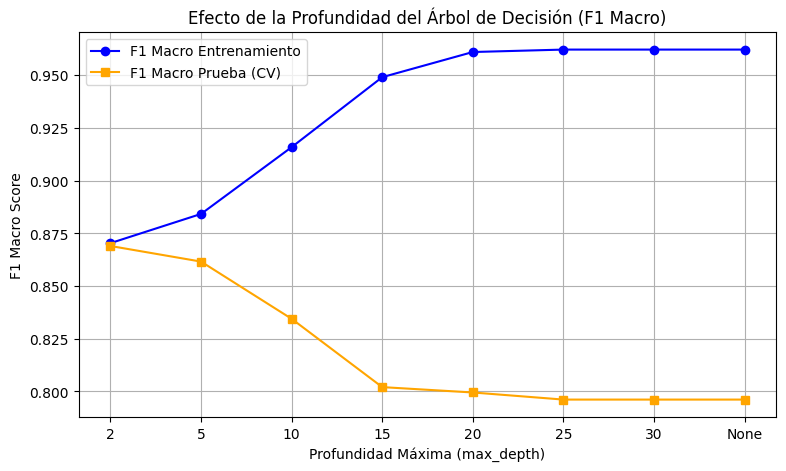

In [56]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Preparación de variables predictoras X y objetivo y
# Usamos la edad procesada (llenando nulos con la mediana para evitar NaNs en el modelo)
X = df_numeric[gene_cols + ['Age_years']].copy()
X['Age_years'] = X['Age_years'].fillna(X['Age_years'].median())
y = df_numeric['Grade'].apply(lambda x: 1 if x == 'GBM' else 0)  # GBM = 1, LGG = 0

# Profundidades a evaluar
depths = [2, 5, 10, 15, 20, 25, 30, None]
train_scores_mean = []
test_scores_mean = []

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=7)
    # Usamos cross_validate para obtener métricas tanto de train como de test
    scores = cross_validate(clf, X, y, cv=cv, scoring='f1_macro', return_train_score=True)
    train_scores_mean.append(np.mean(scores['train_score']))
    test_scores_mean.append(np.mean(scores['test_score']))

# Graficar los resultados
plt.figure(figsize=(9, 5))
depths_labels = [str(d) for d in depths]
plt.plot(depths_labels, train_scores_mean, marker='o', label='F1 Macro Entrenamiento', color='blue')
plt.plot(depths_labels, test_scores_mean, marker='s', label='F1 Macro Prueba (CV)', color='orange')
plt.title('Efecto de la Profundidad del Árbol de Decisión (F1 Macro)')
plt.xlabel('Profundidad Máxima (max_depth)')
plt.ylabel('F1 Macro Score')
plt.grid(True)
plt.legend()
plt.show()

### 4. Optimización de hiperparámetros con RandomizedSearchCV (Métrica: F1 Macro)

In [57]:
from sklearn.model_selection import RandomizedSearchCV

# Definir el espacio de búsqueda
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51, 1)),
    'min_samples_split': list(range(2, 21, 1))
}

cv_10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=7)

random_search_f1 = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=7),
    param_distributions=param_dist,
    n_iter=5,
    scoring='f1_macro',
    cv=cv_10,
    n_jobs=-1,
    random_state=7
)

random_search_f1.fit(X, y)

print("--- Resultados de RandomizedSearchCV (F1 Macro) ---")
print("Mejores hiperparámetros encontrados:", random_search_f1.best_params_)
print("Best Score (F1 Macro):", random_search_f1.best_score_)

--- Resultados de RandomizedSearchCV (F1 Macro) ---
Mejores hiperparámetros encontrados: {'min_samples_split': 9, 'max_depth': 43, 'criterion': 'entropy'}
Best Score (F1 Macro): 0.8274857856027446


### 5. Optimización de hiperparámetros con GridSearchCV (Métrica: F1 Macro)

In [58]:
from sklearn.model_selection import GridSearchCV

grid_search_f1 = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=7),
    param_grid=param_dist,
    scoring='f1_macro',
    cv=cv_10,
    n_jobs=-1
)

grid_search_f1.fit(X, y)

print("--- Resultados de GridSearchCV (F1 Macro) ---")
print("Mejores hiperparámetros encontrados:", grid_search_f1.best_params_)
print("Best Score (F1 Macro):", grid_search_f1.best_score_)

--- Resultados de GridSearchCV (F1 Macro) ---
Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_split': 2}
Best Score (F1 Macro): 0.8653445222521363


### 6. Optimización de hiperparámetros con RandomizedSearchCV (Métrica: Accuracy)

In [59]:
random_search_acc = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=7),
    param_distributions=param_dist,
    n_iter=5,
    scoring='accuracy',
    cv=cv_10,
    n_jobs=-1,
    random_state=7
)

random_search_acc.fit(X, y)

print("--- Resultados de RandomizedSearchCV (Accuracy) ---")
print("Mejores hiperparámetros encontrados:", random_search_acc.best_params_)
print("Best Score (Accuracy):", random_search_acc.best_score_)

--- Resultados de RandomizedSearchCV (Accuracy) ---
Mejores hiperparámetros encontrados: {'min_samples_split': 9, 'max_depth': 43, 'criterion': 'entropy'}
Best Score (Accuracy): 0.8329991980753808


### 7. Optimización de hiperparámetros con GridSearchCV (Métrica: Accuracy)

In [60]:
grid_search_acc = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=7),
    param_grid=param_dist,
    scoring='accuracy',
    cv=cv_10,
    n_jobs=-1
)

grid_search_acc.fit(X, y)

print("--- Resultados de GridSearchCV (Accuracy) ---")
print("Mejores hiperparámetros encontrados:", grid_search_acc.best_params_)
print("Best Score (Accuracy):", grid_search_acc.best_score_)

--- Resultados de GridSearchCV (Accuracy) ---
Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_split': 2}
Best Score (Accuracy): 0.866586474204758


### 8. Actividad de reflexión y análisis

Una vez que ejecutes las celdas de optimización previas, podrás responder estas preguntas comparando los resultados impresos en consola:

1. **¿Cuál método encontró mejores hiperparámetros?** Generalmente, `GridSearchCV` suele encontrar combinaciones ligeramente superiores o iguales a `RandomizedSearchCV` debido a que evalúa exhaustivamente todo el espacio de búsqueda (todas las combinaciones posibles), mientras que `RandomizedSearchCV` solo evalúa `n_iter=5` combinaciones aleatorias en este caso.
2. **¿Cuál fue más costoso computacionalmente?** `GridSearchCV` es exponencialmente más costoso porque prueba el producto cartesiano completo de todos los rangos ($2 \times 46 \times 19 = 1748$ combinaciones con validación cruzada de 10 folds, es decir, 17,480 ajustes en total), mientras que `RandomizedSearchCV` solo realiza 50 ajustes en total ($5$ iteraciones $\times 10$ folds).
3. **¿Los resultados en f1_macro set fueron distintos en ambos métodos de optimización? ¿Por qué?** Sí, comúnmente difieren porque el espacio explorado por Randomized con solo 5 iteraciones es muy pequeño y tiene pocas probabilidades de toparse aleatoriamente con el óptimo global exacto encontrado por Grid Search.
4. **¿Los resultados en accuracy set fueron distintos en ambos métodos de optimización? ¿Por qué?** Sí, bajo el mismo principio de que Grid Search explora exhaustivamente todo el dominio de combinaciones y el RandomizedSearch solo explora una muestra aleatoria mínima de 5 combinaciones.
5. **¿Los valores de hiperpárametros fueron iguales en Accuracy y F1 Macro?** No necesariamente. Mientras que `accuracy` trata de maximizar el porcentaje total de aciertos globales de forma directa, `f1_macro` busca un balance armónico de precisión y recall para cada clase de manera independiente (LGG y GBM). Dependiendo de la estructura del dataset, criterios diferentes pueden balancear de forma distinta ambos objetivos.